In [1]:
%load_ext autoreload
%autoreload 2
import uproot
import numpy as np
import matplotlib.pyplot as plt
import awkward as ak
import sys
sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools/")
import analysisTools as tools
import plotTools as ptools
import utils
import analysisSubroutines as routines
import importlib
import coffea.util as util
import time
import json
import os
from analysisTools import loadSchema
from analysisTools import Analyzer
from analysisTools import iDMeProcessor
from analysisTools import loadSchema
import analysisTools as tools
import analysisSubroutines as routines
import importlib
import coffea.util as util
import time
import json
import os

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/TestOct20.coffea"

sig_histo = util.load(f_sig) [0]
print (sig_histo)

{'dEta': Hist(
  StrCategory(['sig_2022_Mchi-55p0_dMchi-10p0_ctau-100', 'sig_2022_Mchi-11p0_dMchi-2p0_ctau-100', 'sig_2022_Mchi-110p0_dMchi-20p0_ctau-100'], growth=True, name='samp', label='Sample Name'),
  StrCategory(['cut0'], growth=True, name='cut', label='Cut Applied'),
  Regular(200, -5, 5, name='dEta'),
  storage=Weight()) # Sum: WeightedSum(value=4.01915e+06, variance=4.01915e+06) (WeightedSum(value=4.01977e+06, variance=4.01977e+06) with flow), 'dPhi': Hist(
  StrCategory(['sig_2022_Mchi-55p0_dMchi-10p0_ctau-100', 'sig_2022_Mchi-11p0_dMchi-2p0_ctau-100', 'sig_2022_Mchi-110p0_dMchi-20p0_ctau-100'], growth=True, name='samp', label='Sample Name'),
  StrCategory(['cut0'], growth=True, name='cut', label='Cut Applied'),
  Regular(200, -5, 5, name='dPhi'),
  storage=Weight()) # Sum: WeightedSum(value=4.01977e+06, variance=4.01977e+06), 'dR': Hist(
  StrCategory(['sig_2022_Mchi-55p0_dMchi-10p0_ctau-100', 'sig_2022_Mchi-11p0_dMchi-2p0_ctau-100', 'sig_2022_Mchi-110p0_dMchi-20p0_ctau-100

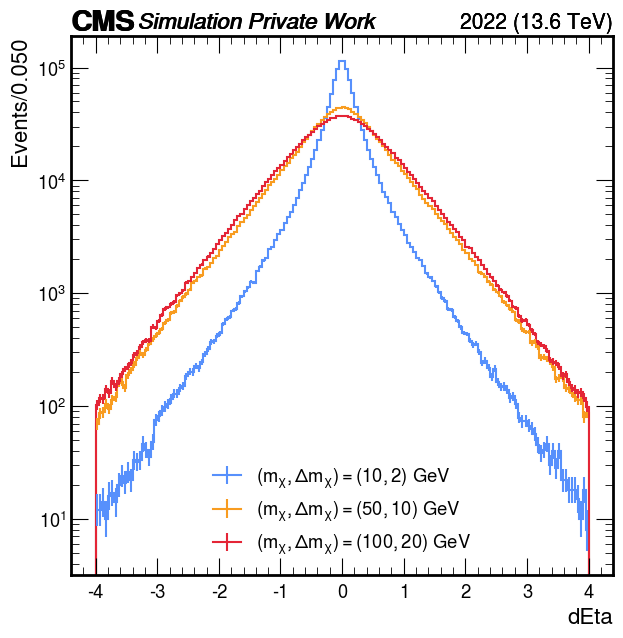

In [6]:
fig, ax = plt.subplots(figsize=(7,7))

# Plot settings
plot_dict = {
    'variable':'dEta',
    'cut': 'cut0',
    'year': 2022
}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': [-4,4],     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True,
    'doLogx': False,
    'doDensity': False,
    'doYerr': True,
    'xlabel': None,
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'gen_ele_vxy10_m110.png'
}

#signal points
samples = {
    10:
    {

        0.2: [100],

    },

   
    50:
    {

        0.2: [100],
    },
    
    
    100:
    {   
         0.2: [100],
    }

}



h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            h_list_lpt.append(h_lpt)            
            if h_sum_lpt is None:
                h_sum_lpt = h_lpt.copy()
            else:
                h_sum_lpt += h_lpt



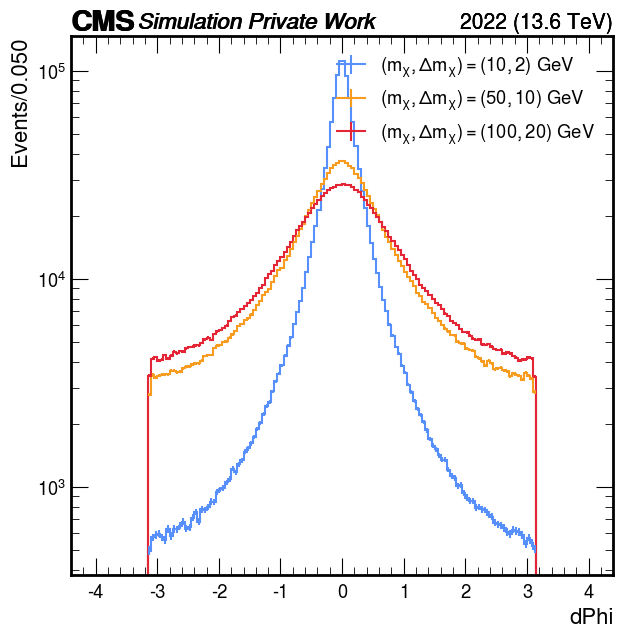

In [9]:
fig, ax = plt.subplots(figsize=(7,7))

# Plot settings
plot_dict = {
    'variable':'dPhi',
    'cut': 'cut0',
    'year': 2022
}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': [-4,4],     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True,
    'doLogx': False,
    'doDensity': False,
    'doYerr': True,
    'xlabel': None,
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'gen_ele_vxy10_m110.png'
}
#signal points
samples = {
    10:
    {

        0.2: [100],

    },

   
    50:
    {

        0.2: [100],
    },
    
    
    100:
    {   
         0.2: [100],
    }

}



h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            h_list_lpt.append(h_lpt)            
            if h_sum_lpt is None:
                h_sum_lpt = h_lpt.copy()
            else:
                h_sum_lpt += h_lpt



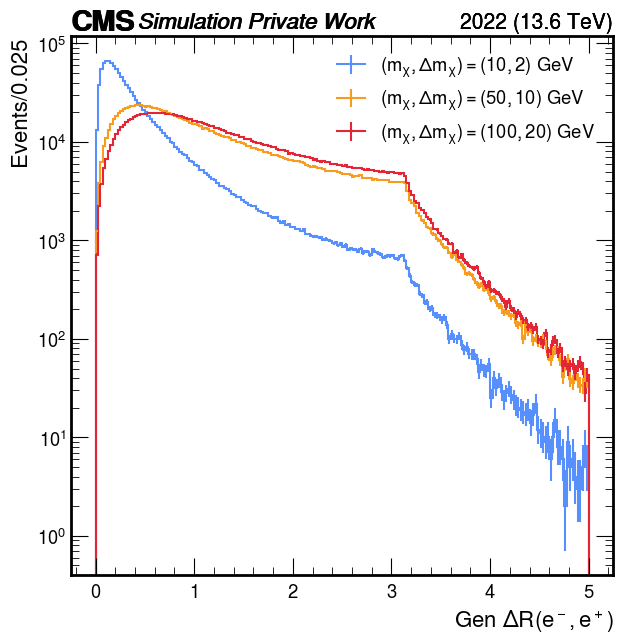

In [10]:
fig, ax = plt.subplots(figsize=(7,7))

# Plot settings
plot_dict = {
    'variable':'dR',
    'cut': 'cut0',
    'year': 2022
}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True,
    'doLogx': False,
    'doDensity': False,
    'doYerr': True,
    'xlabel': r'Gen $\Delta R(e^-, e^+)$',
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'gen_ele_vxy10_m110.png'
}

#signal points

#signal points
samples = {
    10:
    {

        0.2: [100],

    },

   
    50:
    {

        0.2: [100],
    },
    
    
    100:
    {   
         0.2: [100],
    }

}



h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            h_list_lpt.append(h_lpt)            
            if h_sum_lpt is None:
                h_sum_lpt = h_lpt.copy()
            else:
                h_sum_lpt += h_lpt
